# 02 — Data Preprocessing (Week 3)
**Goal:** turn the raw CRMLS monthly files into clean, model-ready data for predicting `ClosePrice`.

Week 3 checklist from the game plan, and the simple method used for each:

| Task | Method |
|---|---|
| Missing values | Drop rows only when the target or a core field is broken. Otherwise **median fill + "was missing" flag** |
| Encoding | Yes/No → **1/0**. County → **one-hot**. ZIP → **average log price of that ZIP** |
| Scaling | **Log** the skewed columns, then **standardize** (mean 0, sd 1) |
| Train/test split | **Test = latest month** (May 2026). **Train = the X months before it.** X is tuned on earlier months |

**The one rule that matters most:** anything that is *learned from data* (a median, a ZIP's average price, a scaling factor) is learned from the **training rows only**, then applied to the test rows. Otherwise the test month leaks into training and the score looks better than it really is.

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load the data
Only the columns we plan to use are read. Everything else is left out on purpose:

| Left out | Why |
|---|---|
| ListPrice, OriginalListPrice, DaysOnMarket, contract dates | **Leakage.** Only known once a home is listed or sold. The model must price *any* home, including ones not for sale |
| Agent / office / ID / address columns | Describe the sale or the listing, not the house |
| Tax, Waterfront, Basement, BuilderName, school names, … | Mostly empty (Week 2) |
| LotSizeAcres, LotSizeArea | Same information as LotSizeSquareFeet |

In [2]:
TARGET = "ClosePrice"
NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
           "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
CATEGORICAL = ["CountyOrParish", "PostalCode"]
USE = ["ListingKey", "CloseDate", "PropertyType", "PropertySubType", TARGET] + NUMERIC + BINARY + CATEGORICAL

frames = []
for f in sorted(glob.glob("*CRMLSSold*.csv")):
    d = pd.read_csv(f, usecols=USE, low_memory=False)
    d["SourceMonth"] = re.search(r"CRMLSSold(\d{6})", f).group(1)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)

print(f"{len(frames)} files, {len(raw):,} rows")
print("Months:", ", ".join(sorted(raw["SourceMonth"].unique())))

27 files, 591,028 rows
Months: 202401, 202402, 202403, 202404, 202405, 202406, 202407, 202408, 202409, 202410, 202411, 202412, 202501, 202502, 202503, 202504, 202505, 202506, 202507, 202510, 202511, 202512, 202601, 202602, 202603, 202604, 202605


> **Note:** Aug and Sep 2025 are missing from the download. That matters when we choose longer training windows in section 6.

## 2. Cleaning (fixed rules, safe to run on all months at once)
### 2.1 Single-family homes only, no duplicates

In [3]:
df = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
print(f"Single-family sales:        {len(df):,}")

# the same listing can appear in two monthly files -> keep the newest record
df = df.sort_values("SourceMonth").drop_duplicates("ListingKey", keep="last")
print(f"After removing duplicates:  {len(df):,}")

Single-family sales:        297,596


After removing duplicates:  297,341


### 2.2 Remove impossible sales
A home that "sold" for $1, or a 45-bedroom house, is a typing error. We **drop the row** only when the price, size, beds or baths are impossible, because those are the most important fields. The bounds are loose on purpose, so real luxury homes and small cabins stay in.

In [4]:
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")
price_per_sqft = df[TARGET] / df["LivingArea"]

ok = (df["CloseDate"].notna()
      & df[TARGET].between(50_000, 30_000_000)
      & df["LivingArea"].between(300, 20_000)
      & price_per_sqft.between(25, 5_000)
      & df["BedroomsTotal"].between(1, 15)
      & df["BathroomsTotalInteger"].between(1, 15))

print(f"Dropping {(~ok).sum():,} impossible sales ({(~ok).mean():.2%} of the data)")
df = df[ok]

Dropping 749 impossible sales (0.25% of the data)


### 2.3 Blank out bad values in less important columns
For the other columns we don't throw away the whole sale. We set the bad value to blank (NaN) and fill it later, like any other missing value.

In [5]:
df.loc[~df["YearBuilt"].between(1850, 2027), "YearBuilt"] = np.nan
df.loc[df["LotSizeSquareFeet"] <= 0, "LotSizeSquareFeet"] = np.nan
df.loc[df["GarageSpaces"] > 20, "GarageSpaces"] = np.nan
outside_ca = ~(df["Latitude"].between(32.4, 42.1) & df["Longitude"].between(-124.5, -114.1))
df.loc[outside_ca, ["Latitude", "Longitude"]] = np.nan

### 2.4 Fix data types
* ZIP `92126-1234` → `92126`
* Yes/No columns → 1/0. A blank usually means the agent didn't tick the box, so blank → 0.
* Missing coordinates → the middle of the same ZIP. This uses location only, never price, so it can't leak.

In [6]:
df["PostalCode"] = df["PostalCode"].astype(str).str[:5]
df["CountyOrParish"] = df["CountyOrParish"].fillna("Missing")

for col in BINARY:
    df[col] = df[col].fillna(False).astype(int)

print("Missing coordinates before:", df["Latitude"].isna().sum())
for col in ["Latitude", "Longitude"]:
    df[col] = df[col].fillna(df.groupby("PostalCode")[col].transform("median"))
df = df.dropna(subset=["Latitude", "Longitude"])     # the few left have no usable ZIP either
print("Missing coordinates after: ", df["Latitude"].isna().sum())

df = df[["ListingKey", "CloseDate", TARGET] + NUMERIC + BINARY + CATEGORICAL].reset_index(drop=True)
print(f"Clean dataset: {len(df):,} sales x {df.shape[1]} columns")

Missing coordinates before: 2578


Missing coordinates after:  0
Clean dataset: 296,573 sales x 18 columns


## 3. Missing values: drop, impute, or flag?

In [7]:
missing = (df.isna().mean() * 100).round(2)
missing[missing > 0].sort_values(ascending=False).to_frame("% missing")

,% missing
Stories,12.890
GarageSpaces,3.640
LotSizeSquareFeet,1.760
YearBuilt,0.060


**Decision:** no more rows are dropped. What's left is small, and dropping 13% of homes because `Stories` is blank would waste good data.
* **Impute with the median** (learned from training months). The median isn't dragged around by extreme values the way the mean is.
* **Add a 0/1 "was missing" flag** for each column that had blanks. If missing-ness itself tells us something (e.g. rural listings skip `Stories`), the model can learn it.

This happens inside `prepare()` in section 5, so the medians come from the training rows only.

## 4. Why these encodings and scales
### Skewed columns → log
Price, living area and lot size have a long right tail: a few huge values. Taking the log pulls them in so one mansion doesn't dominate a linear model. We model **log(price)** and convert back to dollars when scoring.

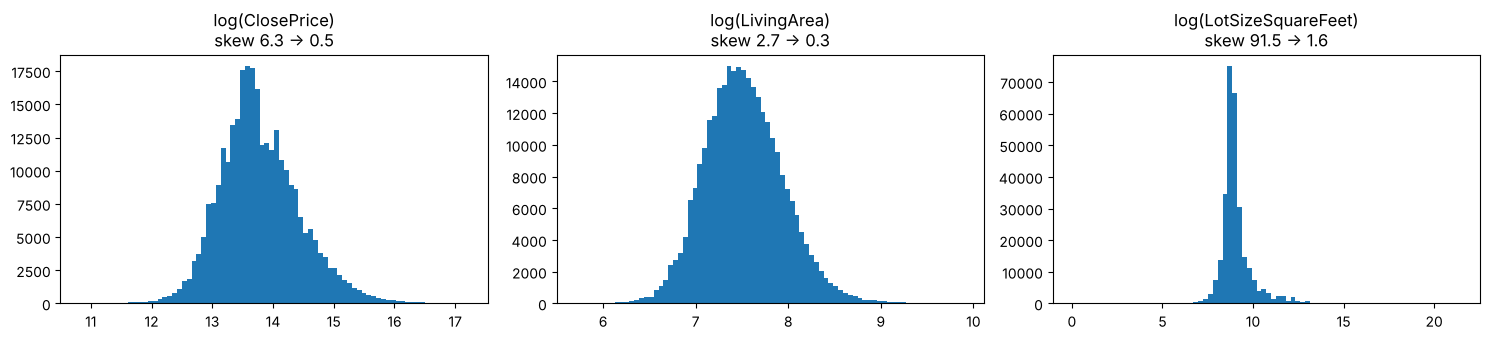

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, [TARGET, "LivingArea", "LotSizeSquareFeet"]):
    s = df[col].dropna()
    ax.hist(np.log1p(s), bins=80)
    ax.set_title(f"log({col})\nskew {s.skew():.1f} → {np.log1p(s).skew():.1f}")
plt.tight_layout(); plt.show()

### Categories → numbers
Models only take numbers.
* **County (~60 values) → one-hot:** one 0/1 column per county.
* **ZIP (~1,600 values) → average log price of that ZIP.** One-hot would make 1,600 mostly-empty columns. Instead each ZIP becomes "how expensive this ZIP is", computed from **training rows only**. ZIPs with few sales are pulled toward the statewide average (*smoothing*), so a ZIP with 2 sales doesn't get an extreme value. ZIPs never seen in training get the statewide average.

In [9]:
zip_prices = df.groupby("PostalCode")[TARGET].agg(sales="size", median_price="median")
zip_prices.query("sales >= 100").sort_values("median_price").iloc[[0, 1, 2, -3, -2, -1]]

,sales,median_price
PostalCode,,
92225,198,"240,000.000"
95422,224,"249,500.000"
95423,107,"265,000.000"
92661,111,"6,299,000.000"
92657,158,"7,550,000.000"
94027,111,"7,800,000.000"


### Standardize
After the logs, every numeric column is rescaled to mean 0 and standard deviation 1 (`StandardScaler`, fit on training rows). Linear Regression (Week 4) needs columns on comparable scales. Tree models (Week 5) don't care, but it doesn't hurt them.

## 5. `prepare()`: learn on train, apply to both

In [10]:
ZIP_SMOOTHING = 20   # a ZIP needs ~20 sales before its own average outweighs the statewide one


def prepare(train, test):
    """Learn medians, ZIP prices, county columns and scaling from `train`; apply them to both."""
    train, test = train.copy(), test.copy()

    # 1) median fill + "was missing" flags
    medians = train[NUMERIC].median()
    for col in NUMERIC:
        if train[col].isna().any():
            train[f"{col}_missing"] = train[col].isna().astype(int)
            test[f"{col}_missing"] = test[col].isna().astype(int)
    train[NUMERIC] = train[NUMERIC].fillna(medians)
    test[NUMERIC] = test[NUMERIC].fillna(medians)

    # 2) log the skewed columns
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        train[col], test[col] = np.log1p(train[col]), np.log1p(test[col])

    # 3) ZIP -> smoothed average log price (training rows only)
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train["PostalCode"]).agg(["mean", "count"])
    zip_value = (stats["count"] * stats["mean"] + ZIP_SMOOTHING * overall) / (stats["count"] + ZIP_SMOOTHING)
    train["ZipPrice"] = train["PostalCode"].map(zip_value)
    test["ZipPrice"] = test["PostalCode"].map(zip_value).fillna(overall)   # unseen ZIP -> statewide average

    # 4) county one-hot; test gets exactly the training columns (unseen county -> all zeros)
    X_train = pd.get_dummies(train.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                             columns=["CountyOrParish"], dtype=int)
    X_test = pd.get_dummies(test.drop(columns=["ListingKey", "CloseDate", TARGET, "PostalCode"]),
                            columns=["CountyOrParish"], dtype=int).reindex(columns=X_train.columns, fill_value=0)

    # 5) standardize the continuous columns
    scale_cols = NUMERIC + ["ZipPrice"]
    scaler = StandardScaler().fit(X_train[scale_cols])
    X_train[scale_cols] = scaler.transform(X_train[scale_cols])
    X_test[scale_cols] = scaler.transform(X_test[scale_cols])

    return X_train, X_test, np.log(train[TARGET]), test[TARGET]


def time_split(df, test_month, months_back):
    """Test = one calendar month. Train = the `months_back` months right before it."""
    month = df["CloseDate"].dt.to_period("M")
    test_month = pd.Period(test_month, "M")
    train = df[(month >= test_month - months_back) & (month < test_month)]
    test = df[month == test_month]
    return train, test

**Check:** after `prepare()` there are no blanks left, train and test have the same columns, and the scaled training columns have mean 0 and sd 1.

In [11]:
train, test = time_split(df, "2026-05", 6)
X_train, X_test, y_train, y_test = prepare(train, test)

assert X_train.notna().all().all() and X_test.notna().all().all(), "blanks left after prepare()"
assert list(X_train.columns) == list(X_test.columns), "train/test columns differ"
assert train["CloseDate"].max() < test["CloseDate"].min(), "training data is not all before the test month"

print(f"X_train {X_train.shape}, X_test {X_test.shape}")
X_train[NUMERIC + ["ZipPrice"]].describe().T[["mean", "std", "min", "max"]]

X_train (59250, 77), X_test (11991, 77)


,mean,std,min,max
LivingArea,-0.000,1.000,-4.120,5.187
LotSizeSquareFeet,0.000,1.000,-8.711,11.864
BedroomsTotal,0.000,1.000,-2.599,11.988
BathroomsTotalInteger,-0.000,1.000,-1.462,10.160
YearBuilt,0.000,1.000,-4.417,1.797
GarageSpaces,0.000,1.000,-2.213,20.169
Stories,0.000,1.000,-0.677,1.477
Latitude,0.000,1.000,-1.288,4.265
Longitude,-0.000,1.000,-3.051,2.314
ZipPrice,-0.000,1.000,-2.543,3.417


## 6. Train/test split and choosing X
* **Test month:** May 2026 (the latest month).
* **Train:** the X months right before it.

We split **by time, not randomly**: in real use we always price future sales with past sales, so we test the same way.

**Choosing X without peeking at May:** we pretend March 2026 and April 2026 are the test month, train on the X months before each, and score a plain Linear Regression. The X with the best average R² wins. Only then do we touch May, **once**.

In [12]:
def score(train, test):
    X_train, X_test, y_train, y_test = prepare(train, test)
    model = LinearRegression().fit(X_train, y_train)
    return r2_score(y_test, np.exp(model.predict(X_test)))     # R² in dollars


rows = []
for X in [1, 2, 3, 4, 6, 9, 12, 18, 24]:
    for practice_month in ["2026-03", "2026-04"]:
        train, practice = time_split(df, practice_month, X)
        rows.append({"X_months": X, "practice_month": practice_month,
                     "train_rows": len(train), "R2": score(train, practice)})

results = pd.DataFrame(rows)
table = results.pivot(index="X_months", columns="practice_month", values="R2")
table["average_R2"] = table.mean(axis=1)
table["train_rows (Apr)"] = results.query("practice_month == '2026-04'").set_index("X_months")["train_rows"]
table

practice_month,2026-03,2026-04,average_R2,train_rows (Apr)
X_months,,,,
1,0.655,0.709,0.682,11147
2,0.689,0.718,0.704,19667
3,0.710,0.727,0.719,27125
4,0.727,0.734,0.730,37549
6,0.732,0.745,0.738,59240
9,0.739,0.749,0.744,71323
12,0.753,0.758,0.755,106532
18,0.755,0.759,0.757,167604
24,0.755,0.759,0.757,243146


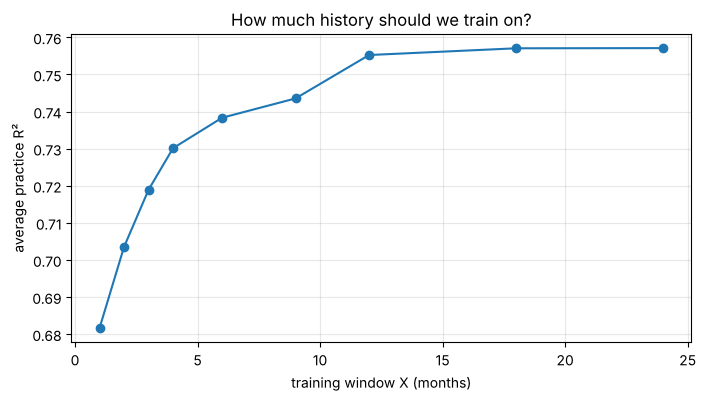

Chosen training window: X = 12 months


In [13]:
plt.figure(figsize=(8, 4))
plt.plot(table.index, table["average_R2"], marker="o")
plt.xlabel("training window X (months)"); plt.ylabel("average practice R²")
plt.title("How much history should we train on?"); plt.grid(alpha=0.3); plt.show()

# shortest window within 0.005 of the best: newer prices, faster training, same accuracy
best = table["average_R2"].max()
BEST_X = int(table.index[table["average_R2"] >= best - 0.005].min())
print(f"Chosen training window: X = {BEST_X} months")

**Reading the result:**
* Very short windows (1–2 months) have too few sales per ZIP, so the ZIP averages are noisy (R² ≈ 0.68–0.70).
* R² keeps climbing up to about **12 months**, then goes flat. 18 and 24 months add twice the data for almost no gain.
* When scores are this close, the **shortest good window** is the safer pick: house prices drift over time, so newer data matches the test month better. On this run the rule picks **X = 12**.
* For the May 2026 test month, windows longer than 7 months reach back past the missing Aug–Sep 2025 files, so they contain 2 fewer months of data than their label says.

### Final split (test once on May 2026)

In [14]:
train, test = time_split(df, "2026-05", BEST_X)
print(f"Train: {train['CloseDate'].min():%b %Y} – {train['CloseDate'].max():%b %Y}, {len(train):,} sales")
print(f"Test:  May 2026, {len(test):,} sales")
print(f"Preview Linear Regression test R²: {score(train, test):.3f}")

Train: May 2025 – Apr 2026, 106,696 sales
Test:  May 2026, 11,991 sales


Preview Linear Regression test R²: 0.779


This is a **preview** to prove the pipeline works end to end. The official baseline is next week (Week 4).

## 7. Save the cleaned CSV

In [15]:
df["Split"] = "unused"
df.loc[train.index, "Split"] = "train"
df.loc[test.index, "Split"] = "test"

df.to_csv("cleaned_sfr.csv", index=False)
print(f"cleaned_sfr.csv: {len(df):,} rows x {df.shape[1]} columns")
df["Split"].value_counts().to_frame("rows")

cleaned_sfr.csv: 296,573 rows x 19 columns


,rows
Split,
unused,177886
train,106696
test,11991


`cleaned_sfr.csv` holds the rows **after cleaning but before** median fill, encoding and scaling. Those steps have to be re-learned from whatever training window a later notebook uses, so Week 4+ should load this file and call `prepare(train, test)` again.

## Summary
* **Scope:** Residential single-family sales, Jan 2024 – May 2026 (Aug–Sep 2025 missing). Duplicates removed.
* **Cleaning:** dropped sales with impossible price, size, beds or baths (well under 1%). Other bad values were blanked, not deleted.
* **Columns:** listing-time fields (ListPrice, DaysOnMarket, …) removed to avoid leakage. Agent, ID and near-empty columns removed.
* **Missing values:** median fill + "was missing" flag, learned from training rows only. Yes/No blanks → 0. Missing coordinates → ZIP centre.
* **Encoding:** Yes/No → 1/0, county → one-hot, ZIP → smoothed average log price from training rows.
* **Scaling:** log on price, living area and lot size, then standardization.
* **Split:** test = May 2026, train = the X months before. X chosen on March/April 2026 practice months → **X = 12** (May 2025 – Apr 2026, ~107K sales).
* **Preview:** a plain Linear Regression already reaches **R² ≈ 0.78** on May 2026 without ListPrice.